In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
REPORT_DIR = Path("reports")
XAI_DIR = REPORT_DIR / "xai"

REPORT_DIR.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")


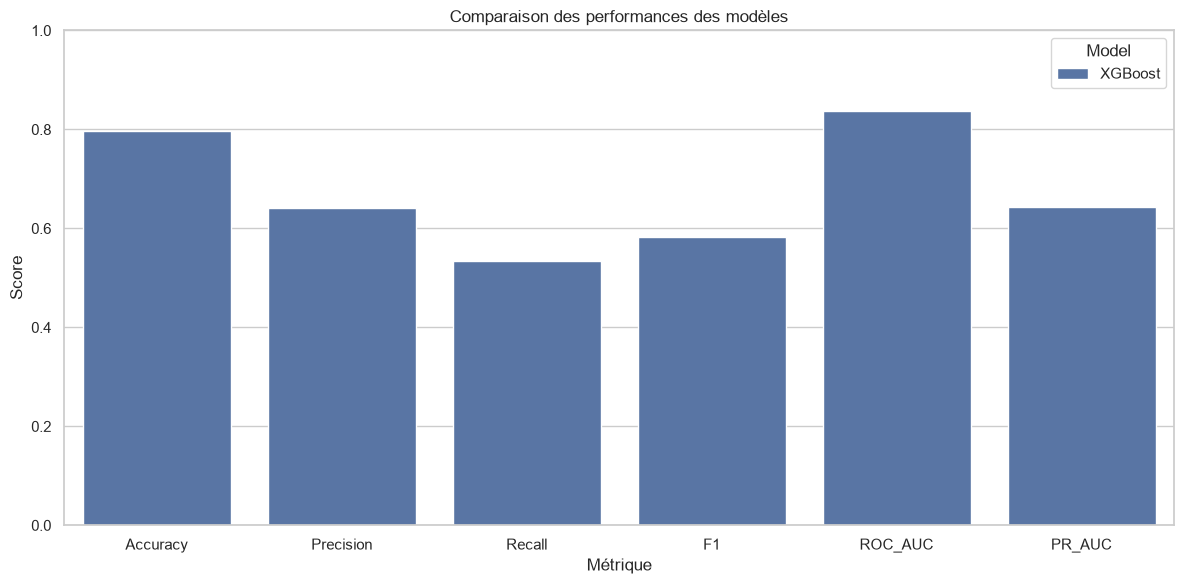

In [3]:

results_path = REPORT_DIR / "model_comparison.csv"

if results_path.exists():
    results = pd.read_csv(results_path)

    metrics = [
        col for col in
        ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]
        if col in results.columns
    ]

    if metrics:
        plot_data = results.melt(
            id_vars="Model",
            value_vars=metrics,
            var_name="Metric",
            value_name="Score"
        )

        plt.figure(figsize=(12, 6))
        sns.barplot(
            data=plot_data,
            x="Metric",
            y="Score",
            hue="Model"
        )
        plt.ylim(0, 1)
        plt.title("Comparaison des performances des modèles")
        plt.ylabel("Score")
        plt.xlabel("Métrique")
        plt.tight_layout()
        plt.savefig(
            REPORT_DIR / "model_comparison.png",
            dpi=150
        )
        plt.show()
else:
    print("Fichier model_comparison.csv introuvable.")

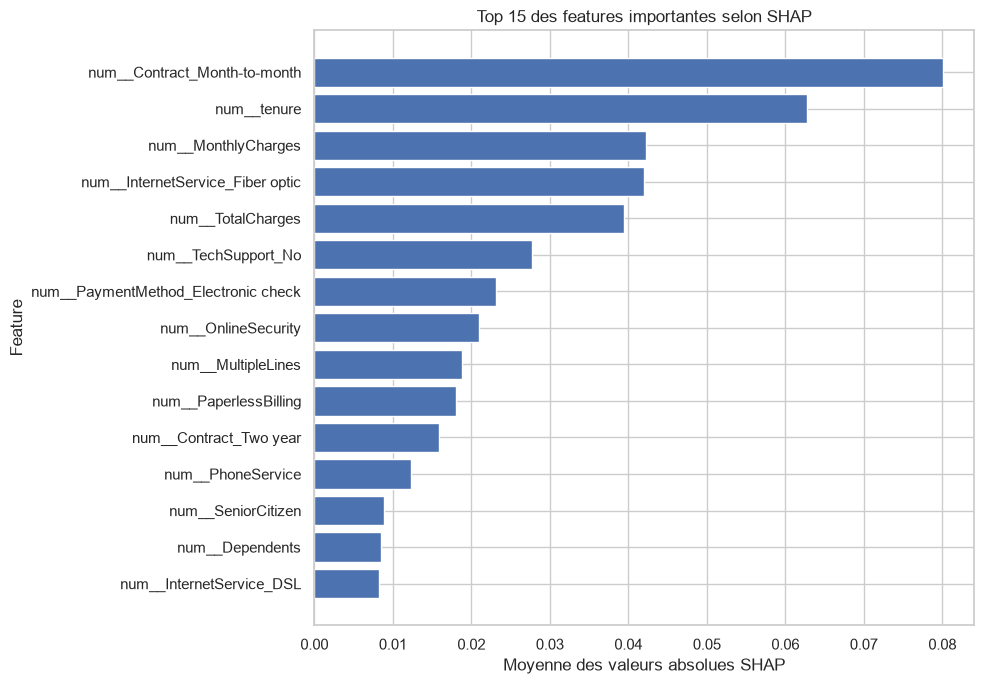

In [4]:
importance_path = XAI_DIR / "global_feature_importance.csv"

if importance_path.exists():
    importance = pd.read_csv(importance_path)
    importance = importance.nlargest(15, "Mean_Absolute_SHAP")
    importance = importance.sort_values("Mean_Absolute_SHAP")

    plt.figure(figsize=(10, 7))
    plt.barh(
        importance["Feature"],
        importance["Mean_Absolute_SHAP"]
    )
    plt.title("Top 15 des features importantes selon SHAP")
    plt.xlabel("Moyenne des valeurs absolues SHAP")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.savefig(
        XAI_DIR / "shap_global_importance.png",
        dpi=150
    )
    plt.show()
else:
    print("Fichier global_feature_importance.csv introuvable.")

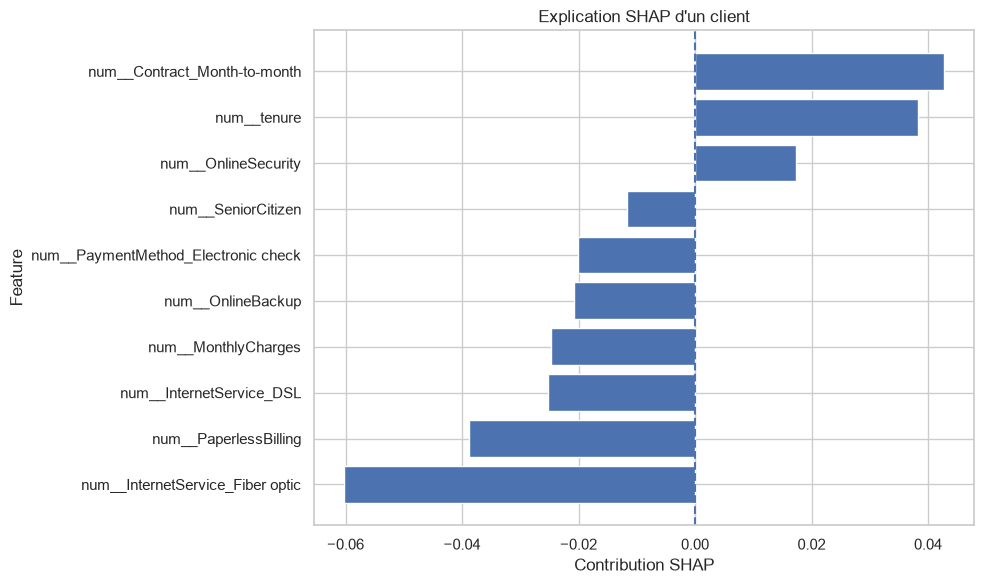

In [5]:
local_path = XAI_DIR / "local_explanation.csv"

if local_path.exists():
    local = pd.read_csv(local_path)
    local = local.nlargest(10, "Abs_SHAP")
    local = local.sort_values("SHAP_Value")

    plt.figure(figsize=(10, 6))
    plt.barh(
        local["Feature"],
        local["SHAP_Value"]
    )
    plt.axvline(0, linestyle="--")
    plt.title("Explication SHAP d'un client")
    plt.xlabel("Contribution SHAP")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.savefig(
        XAI_DIR / "shap_local_explanation.png",
        dpi=150
    )
    plt.show()
else:
    print("Fichier local_explanation.csv introuvable.")

Graphique LIME disponible : reports\xai\lime_explanation.png


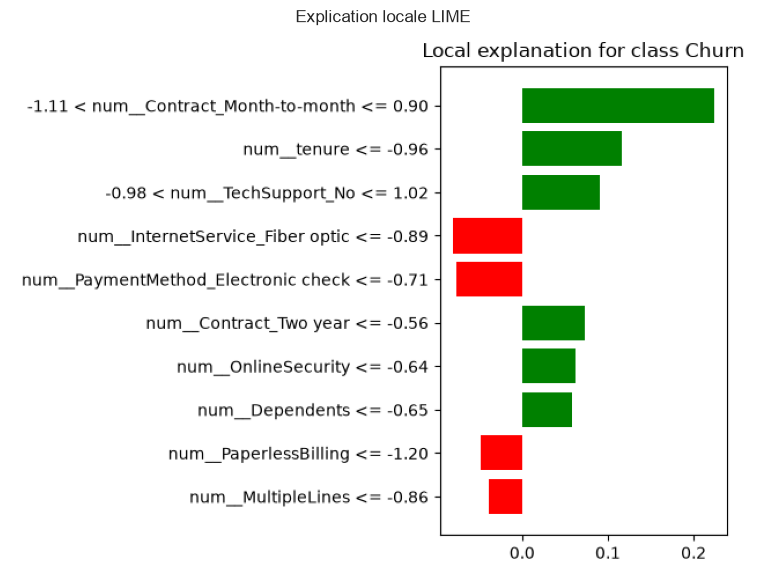


Visualisation terminée.


In [6]:
lime_path = XAI_DIR / "lime_explanation.png"

if lime_path.exists():
    print(f"Graphique LIME disponible : {lime_path}")
    lime_image = plt.imread(lime_path)

    plt.figure(figsize=(10, 6))
    plt.imshow(lime_image)
    plt.axis("off")
    plt.title("Explication locale LIME")
    plt.tight_layout()
    plt.show()
else:
    print("Fichier lime_explanation.png introuvable.")

print("\nVisualisation terminée.")